# Практическая работа № 6
## Первичный анализ данных (EDA)

**Цель работы:** изучить структуру датасета успеваемости учащихся, определить типы признаков, проверить наличие пропусков, получить описательную статистику, построить графики и сформулировать выводы.

**Датасет:** Students Performance in Exams.

**Инструменты:** Python, Pandas, Matplotlib, Google Colab.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

In [2]:
uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Датасет успешно загружен!")

Saving StudentsPerformance.csv to StudentsPerformance.csv
Датасет успешно загружен!


In [3]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [4]:
print("Размер таблицы:", df.shape)
print("Количество строк:", df.shape[0])
print("Количество столбцов:", df.shape[1])

Размер таблицы: (1000, 8)
Количество строк: 1000
Количество столбцов: 8


In [5]:
print("Типы данных:")
print(df.dtypes)

Типы данных:
gender                         object
race/ethnicity                 object
parental level of education    object
lunch                          object
test preparation course        object
math score                      int64
reading score                   int64
writing score                   int64
dtype: object


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [7]:
print("Количество пропусков по столбцам:")
print(df.isnull().sum())

print("\nОбщее количество пропусков:")
print(df.isnull().sum().sum())

Количество пропусков по столбцам:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

Общее количество пропусков:
0


In [8]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [9]:
df.describe(include="all")

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
count,1000,1000,1000,1000,1000,1000.00000,1000.000000,1000.000000
unique,2,5,6,2,2,NaN,NaN,NaN
top,female,group C,some college,standard,none,NaN,NaN,NaN
freq,518,319,226,645,642,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,66.08900,69.169000,68.054000
std,NaN,NaN,NaN,NaN,NaN,15.16308,14.600192,15.195657
min,NaN,NaN,NaN,NaN,NaN,0.00000,17.000000,10.000000
25%,NaN,NaN,NaN,NaN,NaN,57.00000,59.000000,57.750000
50%,NaN,NaN,NaN,NaN,NaN,66.00000,70.000000,69.000000
75%,NaN,NaN,NaN,NaN,NaN,77.00000,79.000000,79.000000


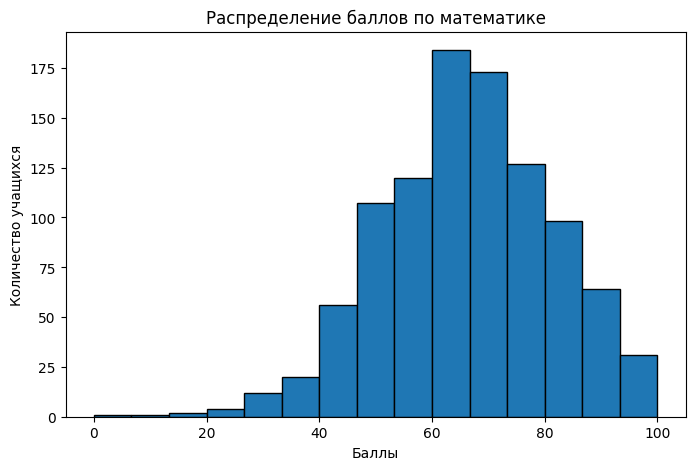

In [10]:
plt.figure(figsize=(8, 5))

plt.hist(df["math score"], bins=15, edgecolor="black")

plt.title("Распределение баллов по математике")
plt.xlabel("Баллы")
plt.ylabel("Количество учащихся")

plt.show()

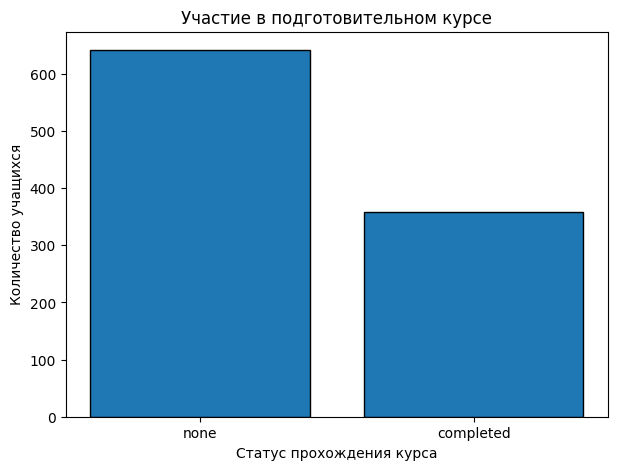

In [11]:
course_counts = df["test preparation course"].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(
    course_counts.index,
    course_counts.values,
    edgecolor="black"
)

plt.title("Участие в подготовительном курсе")
plt.xlabel("Статус прохождения курса")
plt.ylabel("Количество учащихся")

plt.show()

In [12]:
print("Средние баллы в зависимости от подготовки:")

print(
    df.groupby("test preparation course")[
        ["math score", "reading score", "writing score"]
    ].mean().round(2)
)

print("\nСредние баллы в зависимости от типа обеда:")

print(
    df.groupby("lunch")[
        ["math score", "reading score", "writing score"]
    ].mean().round(2)
)

print("\nКоличество учащихся по полу:")

print(df["gender"].value_counts())

Средние баллы в зависимости от подготовки:
                         math score  reading score  writing score
test preparation course                                          
completed                     69.70          73.89          74.42
none                          64.08          66.53          64.50

Средние баллы в зависимости от типа обеда:
              math score  reading score  writing score
lunch                                                 
free/reduced       58.92          64.65          63.02
standard           70.03          71.65          70.82

Количество учащихся по полу:
gender
female    518
male      482
Name: count, dtype: int64


In [13]:
scores = df.groupby("test preparation course")[
    ["math score", "reading score", "writing score"]
].mean()

print("Разница средних баллов: completed минус none")

print((scores.loc["completed"] - scores.loc["none"]).round(2))

Разница средних баллов: completed минус none
math score       5.62
reading score    7.36
writing score    9.91
dtype: float64


## Основные наблюдения

1. **Связь с подготовительным курсом.** Учащиеся, завершившие подготовительный курс, имеют [более высокие / более низкие] средние результаты по [названия предметов]. Это наблюдаемое различие не доказывает, что курс является единственной причиной разницы.

2. **Различия по типу обеда.** Группа с типом питания [standard / free/reduced] показывает более высокие средние баллы по [предметы]. По имеющимся данным нельзя утверждать, что тип питания непосредственно вызвал эту разницу.

3. **Представленность групп.** Наибольшую долю в выборке по подготовительному курсу составляет категория [none / completed]. Поэтому при анализе общих показателей важно учитывать, что группы представлены в разных количествах.